# Задание 1. Разведочный анализ данных 
Построить модель, которая предсказывает общую продолжительность поездок на 
такси в Нью-Йорке. Ваш основной набор данных — это данные, предоставленные 
Комиссией по такси и лимузинам Нью-Йорка, которые включают время посадки, 
географические координаты, количество пассажиров и ряд других переменных. 
Структура данных: 
- id — уникальный идентификатор каждой поездки. 
- vendor_id — код поставщика, связанного с записью о поездке. 
- pickup_datetime — дата и время включения счетчика. 
- passenger_count — количество пассажиров в транспортном средстве (значение, 
введенное водителем). 
- pickup_longitude — долгота места включения счетчика. 
- pickup_latitude — широта места включения счетчика. 
- dropoff_longitude — долгота места отключения счетчика. 
- dropoff_latitude — широта места отключения счетчика. 
- store_and_fwd_flag — этот флаг указывает, хранилась ли запись о поездке в памяти 
транспортного средства перед отправкой поставщику из-за отсутствия подключения к 
серверу. Y = поездка с сохранением и пересылкой; N = поездка без сохранения и пересылки. 
- trip_duration — продолжительность поездки в секундах.

1. Преобразуйте даты в datetime-объекты. 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from haversine import haversine, Unit

# стиль графиков
sns.set_theme(style='whitegrid') # базовый стиль
# цветовая палитра
sns.set_palette('husl')  
# размер графиков по умолчанию
plt.rcParams['figure.figsize'] = (14, 6)  
df = pd.read_csv('train.csv')

# преобразование даты
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

# проверка преобразования
print("Тип данных после преобразования:")
print(df['pickup_datetime'].dtype)
print("\nПервые 5 строк:")
print(df[['pickup_datetime', 'trip_duration']].head())

print("\nИнформация о данных:")
print(f"Всего записей: {len(df)}")
print(f"Диапазон дат: с {df['pickup_datetime'].min()} по {df['pickup_datetime'].max()}")
print(f"Пропущенные значения в trip_duration: {df['trip_duration'].isnull().sum()}")



Тип данных после преобразования:
datetime64[us]

Первые 5 строк:
      pickup_datetime  trip_duration
0 2016-03-14 17:24:55            455
1 2016-06-12 00:43:35            663
2 2016-01-19 11:35:24           2124
3 2016-04-06 19:32:31            429
4 2016-03-26 13:30:55            435

Информация о данных:
Всего записей: 1458640
Диапазон дат: с 2016-01-01 00:00:17 по 2016-06-30 23:59:39
Пропущенные значения в trip_duration: 0


2. Нарисуйте его гистограмму распределения продолжительности поездки.

```
KDE = Kernel Density Estimation
по-русски: ядерная оценка плотности распределения.
Это плавная кривая, которая показывает где данных больше, где меньше
```

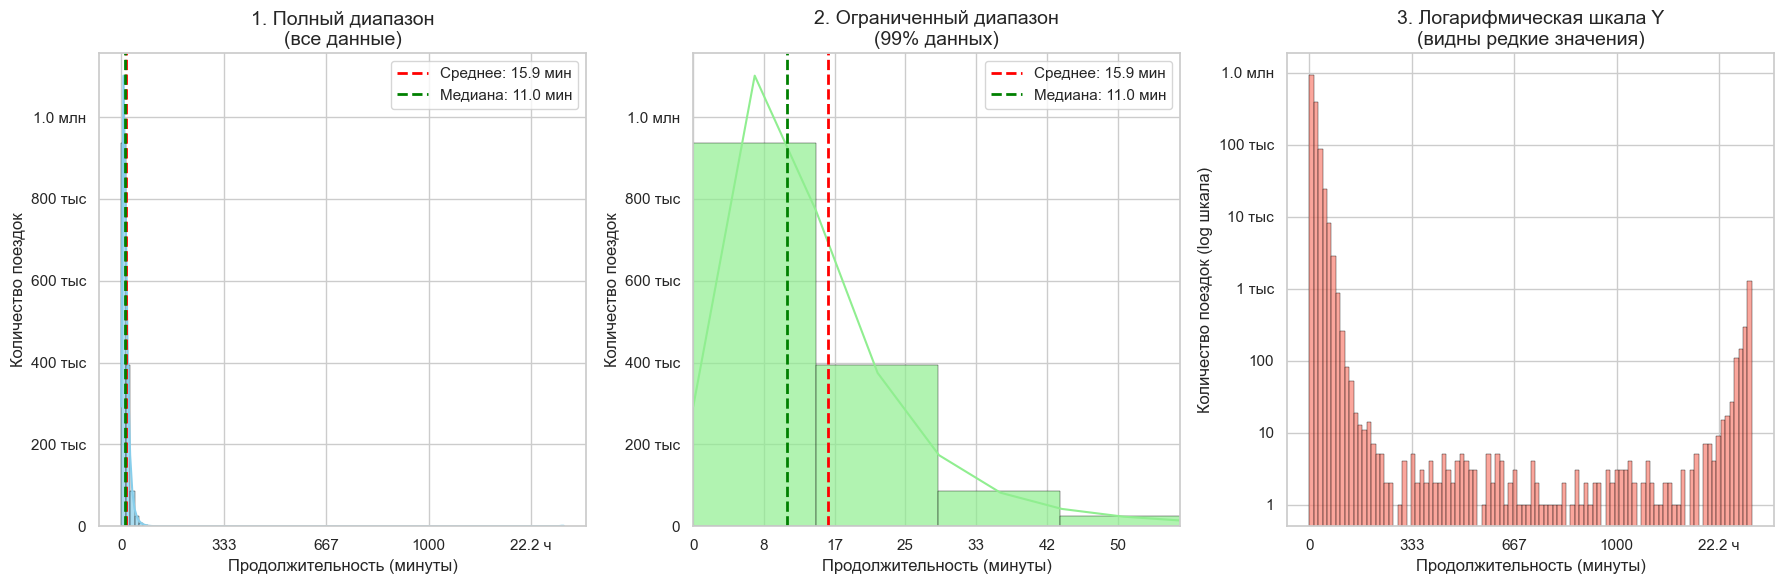

In [90]:
import matplotlib.ticker as ticker

#  форматирование оси X (секунды в минуты/часы)
def seconds_to_minutes(x, pos):
    """Конвертирует секунды в минуты или часы для подписей оси"""
    minutes = x/60
    if minutes > 1000:
        return f'{minutes/60:.1f} ч'  # показываю в часах
    else:
        return f'{minutes:.0f}'

# форматирование для оси Y (человекочитаемые числа)
def human_format_y(y, pos):
    """Форматирует число в человекочитаемый вид для оси Y"""
    if y >= 1e6:
        return f'{y/1e6:.1f} млн'
    elif y >= 1e3:
        return f'{y/1e3:.0f} тыс'
    else:
        return f'{int(y)}'

# будет 3 графика
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1 ПЕРВЫЙ ГРАФИК: Полный диапазон
sns.histplot(data=df, x='trip_duration', bins=100, 
             color='skyblue', edgecolor='black', alpha=0.7,
             kde=True, ax=axes[0], stat='count')
axes[0].set_title('1. Полный диапазон\n(все данные)', fontsize=14)
axes[0].set_xlabel('Продолжительность (минуты)', fontsize=12)
axes[0].set_ylabel('Количество поездок', fontsize=12)

axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(seconds_to_minutes))
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(human_format_y))

# статистика для первого графика
mean_dur = df['trip_duration'].mean()
median_dur = df['trip_duration'].median()
axes[0].axvline(mean_dur, color='red', linestyle='--', linewidth=2, 
                label=f'Среднее: {mean_dur/60:.1f} мин')
axes[0].axvline(median_dur, color='green', linestyle='--', linewidth=2, 
                label=f'Медиана: {median_dur/60:.1f} мин')
axes[0].legend()

# 2 ВТОРОЙ ГРАФИК: Ограниченный диапазон (99% данных)
sns.histplot(data=df, x='trip_duration', bins=100, 
             color='lightgreen', edgecolor='black', alpha=0.7,
             kde=True, ax=axes[1], stat='count')
axes[1].set_xlim(0, df['trip_duration'].quantile(0.99))
axes[1].set_title('2. Ограниченный диапазон\n(99% данных)', fontsize=14)
axes[1].set_xlabel('Продолжительность (минуты)', fontsize=12)
axes[1].set_ylabel('Количество поездок', fontsize=12)

axes[1].xaxis.set_major_formatter(ticker.FuncFormatter(seconds_to_minutes))
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(human_format_y))

# статистика для второго графика
axes[1].axvline(mean_dur, color='red', linestyle='--', linewidth=2, 
                label=f'Среднее: {mean_dur/60:.1f} мин')
axes[1].axvline(median_dur, color='green', linestyle='--', linewidth=2, 
                label=f'Медиана: {median_dur/60:.1f} мин')
axes[1].legend()

# 3. ТРЕТИЙ ГРАФИК: Логарифмическая шкала
sns.histplot(data=df, x='trip_duration', bins=100, 
             color='salmon', edgecolor='black', alpha=0.7,
             ax=axes[2], stat='count')
axes[2].set_yscale('log')
axes[2].set_title('3. Логарифмическая шкала Y\n(видны редкие значения)', fontsize=14)
axes[2].set_xlabel('Продолжительность (минуты)', fontsize=12)
axes[2].set_ylabel('Количество поездок (log шкала)', fontsize=12)

axes[2].xaxis.set_major_formatter(ticker.FuncFormatter(seconds_to_minutes))
axes[2].yaxis.set_major_formatter(ticker.FuncFormatter(human_format_y))

plt.tight_layout()
plt.show()

![Анализ выбросов](./images/task2_emissions.png)
![Анализ выбросов](./images/task2_emissions_deleted.png)

Первый график - с выбросами.
Второй график - без выбросов.

In [91]:
# задаю ограничение
threshold_hours = 24
threshold_seconds = threshold_hours * 3600

# все поездки длиннее порога
outliers = df[df['trip_duration'] > threshold_seconds]

print(f"Поездки длиннее {threshold_hours} часов:")
print(f"Всего найдено: {len(outliers)}")
print("\n" + "="*60)
print(outliers[['id', 'trip_duration', 'pickup_datetime']].sort_values('trip_duration', ascending=False))

Поездки длиннее 24 часов:
Всего найдено: 0

Empty DataFrame
Columns: [id, trip_duration, pickup_datetime]
Index: []


3. Нарисуйте часть гистограммы для редких (малочастотных) значений. 

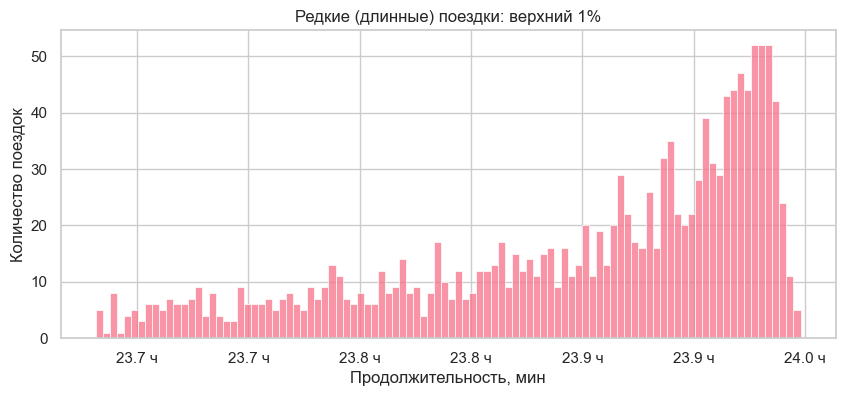

In [92]:
# граница редких значений (0.999-й квантиль)
p999 = df["trip_duration"].quantile(0.999)

fig, axes = plt.subplots(figsize=(10, 4))
sns.histplot(
    df[df["trip_duration"] > p999]["trip_duration"],
    bins=100,
    stat='count',
    ax=axes
)
axes.xaxis.set_major_formatter(ticker.FuncFormatter(seconds_to_minutes))
axes.yaxis.set_major_formatter(ticker.FuncFormatter(human_format_y))
axes.set_title("Редкие (длинные) поездки: верхний 1%")
axes.set_xlabel("Продолжительность, мин")
axes.set_ylabel("Количество поездок")
plt.show()


4. Что можно сказать о целевой переменной по гистограмме её значений? 

    Гистограмма редких значений имеет нерегулярную форму из-за малого числа наблюдений, что не позволяет делать выводы о характере распределения хвоста.

5. В качестве метрики качества использовалось RMSLE. Почему была выбрана именно 
метрика RMSLE, а не RMSE? 

    Метрика RMSLE была выбрана вместо RMSE, поскольку целевая переменная имеет сильно скошенное распределение (большинство значений находится слева) с длинным правым хвостом.

    RMSLE уменьшает влияние редких, но очень больших значений и оценивает относительную ошибку предсказания.

    Это особенно важно в задаче прогнозирования длительности поездки, где ошибка в 2 раза более значима, чем абсолютная разница в секундах.
    
    В отличие от RMSE, RMSLE более устойчива к выбросам и лучше отражает качество модели на типичных поездках.

6. Добавьте колонку с логарифмом целевой переменной log_trip_duration  (воспользуйтесь np.log1p) и нарисуйте гистограмму. 

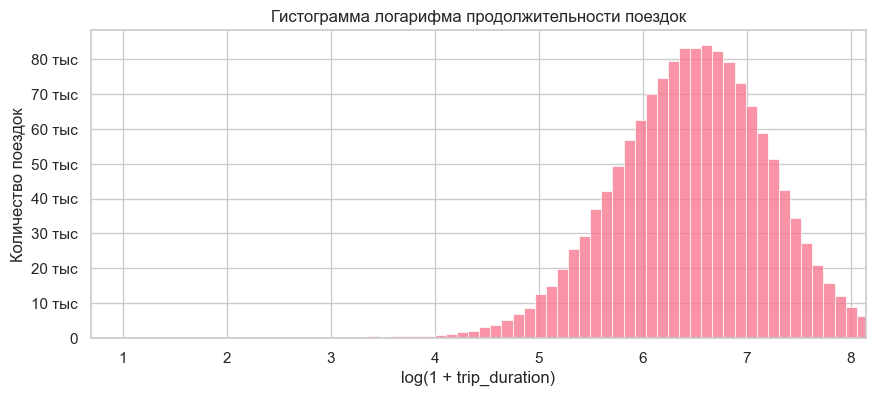

In [93]:
# добавление log_trip_duration
# зачем? сгладить сильно скошенное распределение, сделать хвост более доступным для анализа.
df['log_trip_duration'] = np.log1p(df['trip_duration'])
min_log_trip_duration = df["log_trip_duration"].min()
fig, axes = plt.subplots(figsize=(10, 4))
sns.histplot(
    df["log_trip_duration"],
    bins=100,
    stat='count',
    ax=axes
)
axes.set_xlim(min_log_trip_duration, df['log_trip_duration'].quantile(0.99))
axes.yaxis.set_major_formatter(ticker.FuncFormatter(human_format_y))
axes.set_title("Гистограмма логарифма продолжительности поездок")
axes.set_xlabel("log(1 + trip_duration)")
axes.set_ylabel("Количество поездок")
plt.show()


Распределение логарифма от продолжительности поездки схож с нормальным.

7. Посчитайте значение метрики MSE при константном предсказании. 
```
Константное предсказание = одно и то же число для всех поездок.
Обычно выбирают среднее или медиану целевой переменной (trip_duration).
```

In [94]:
# Константное предсказание - среднее значение
constant_pred = df['trip_duration'].mean()

# Ошибки (разница между реальными и предсказанными)
errors = df['trip_duration'] - constant_pred

# MSE = 1/n (y - y^)^2
mse = np.mean(errors ** 2)

print(f"MSE при константном предсказании: {mse:.2f} секунд^2")
rmse = np.sqrt(mse)
print(f"RMSE при константном предсказании: {rmse:.1f} секунд")
print(f"RMSE при константном предсказании: {rmse/60:.1f} минут")

MSE при константном предсказании: 10057278.13 секунд^2
RMSE при константном предсказании: 3171.3 секунд
RMSE при константном предсказании: 52.9 минут


8. Постройте график зависимости количества поездок от дня в году (например, можно воспользоваться sns.countplot).

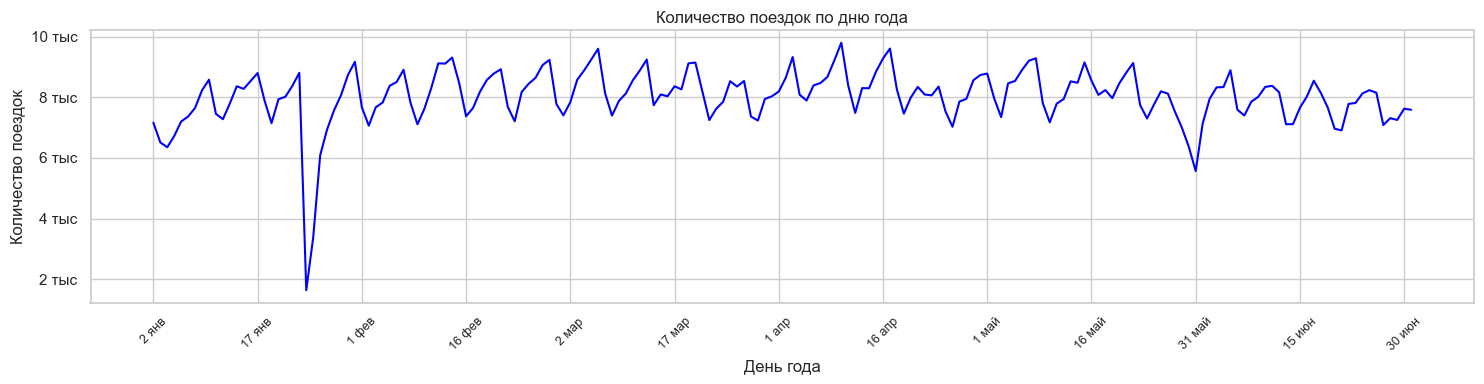

Диапазон дней в году (мин/макс):  1 182


In [95]:
# колонка с датой без времени
df['day_of_year'] = df['pickup_datetime'].dt.dayofyear
daily_counts = df.groupby(df['pickup_datetime'].dt.dayofyear)['id'].count().reset_index()
daily_counts.columns = ['day_of_year', 'trip_count']

months_ru = ['янв','фев','мар','апр','май','июн','июл','авг','сен','окт','ноя','дек']

# делаем человекочитаемые метки
xticklabels = [
    f"{d.day} {months_ru[d.month-1]}" 
    for d in pd.to_datetime(daily_counts['day_of_year'], origin=f'{df["pickup_datetime"].dt.year.min()}-01-01', unit='D')
]

fig, axes = plt.subplots(figsize=(15, 4))
sns.lineplot(data=daily_counts, x='day_of_year', y='trip_count', color='blue', ax=axes)

axes.yaxis.set_major_formatter(ticker.FuncFormatter(human_format_y))
axes.set_title("Количество поездок по дню года")
axes.set_xlabel("День года")
axes.set_ylabel("Количество поездок")

plt.xticks(daily_counts['day_of_year'][::15], xticklabels[::15], rotation=45, fontsize=9)
plt.tight_layout()
plt.show()

print(f"Диапазон дней в году (мин/макс): ", daily_counts['day_of_year'].min(), daily_counts['day_of_year'].max())

9. Вычислите, в какие даты было аномально маленькое количество поездок, найдите информацию о том, что происходило в эти дни в Нью-Йорке. 

In [96]:
daily_counts.sort_values('trip_count').head(10)
threshold = daily_counts['trip_count'].quantile(0.02)
rare_days = daily_counts[daily_counts['trip_count'] < threshold]

print("Дни с аномально малым количеством поездок:")
print(rare_days)
print("Максимальное число поездок в день:", daily_counts['trip_count'].max())

Дни с аномально малым количеством поездок:
     day_of_year  trip_count
22            23        1648
23            24        3383
24            25        6084
150          151        5570
Максимальное число поездок в день: 9796


22-24 января 2016 года в Нью-Йорке из-за снежной бури «Джонас» полностью прекратили автомобильное движение

[Ссылка на вики](https://translated.turbopages.org/proxy_u/en-ru.ru.37000ebf-69a8643a-6f111903-74722d776562/https/en.wikipedia.org/wiki/January_2016_United_States_blizzard)

10. Нарисуйте графики зависимости количества поездок от дня недели и от часов в сутках (воспользуйтесь sns.relplot). Сделайте выводы.

In [97]:
# ПОДГОТОВКА ДАННЫХ ДЛЯ 10-15
# день недели (0 - понедельник, 6 - воскресенье)
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

# час в сутках
df['hour'] = df['pickup_datetime'].dt.hour

# месяц
df['month'] = df['pickup_datetime'].dt.month


weekday_labels = {0:'Пн',1:'Вт',2:'Ср',3:'Чт',4:'Пт',5:'Сб',6:'Вс'}
month_labels = {1:'Янв',2:'Фев',3:'Мар',4:'Апр',5:'Май',6:'Июн',
                7:'Июл',8:'Авг',9:'Сен',10:'Окт',11:'Ноя',12:'Дек'}

weekday_order = ['Пн','Вт','Ср','Чт','Пт','Сб','Вс']
month_order = ['Янв','Фев','Мар','Апр','Май','Июн']

df['day_name'] = df['day_of_week'].map(weekday_labels)
df['month_name'] = df['month'].map(month_labels)

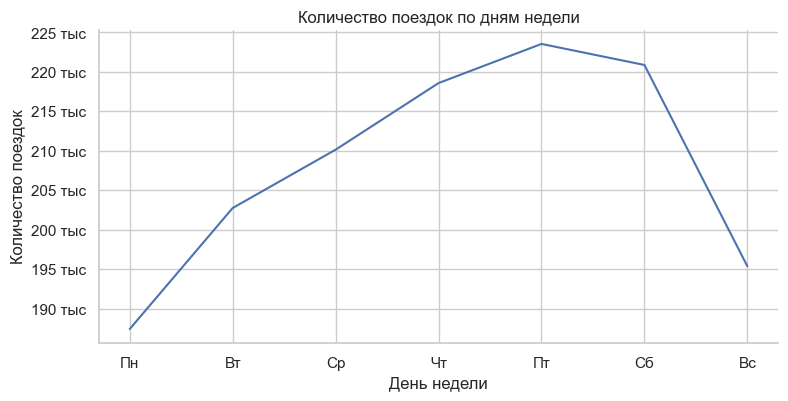

In [98]:
'''
Зависимость количества поездок от дня недели
'''
sns.set_theme(style='whitegrid')

# количество поездок по дням недели
daily_week_counts = (
    df
    .groupby('day_name')['id']
    .count()
    .reset_index()
)

daily_week_counts['day_name'] = pd.Categorical(
    daily_week_counts['day_name'],
    categories=['Пн','Вт','Ср','Чт','Пт','Сб','Вс'],
    ordered=True
)

daily_week_counts = daily_week_counts.sort_values('day_name')
figure = sns.relplot(
    data=daily_week_counts,
    x='day_name',
    y='id',
    kind='line',
    height=4,
    aspect=2
)


figure.ax.yaxis.set_major_formatter(plt.FuncFormatter(human_format_y))

plt.title("Количество поездок по дням недели")
plt.xlabel("День недели")
plt.ylabel("Количество поездок")
plt.show()

Вывод: в будние дни начинается монотонный рост количества поездок, в ПТ наблюдается пик количества поездок, в выходные количество поездок монотонно убывает, исходя из имеющейся выборки

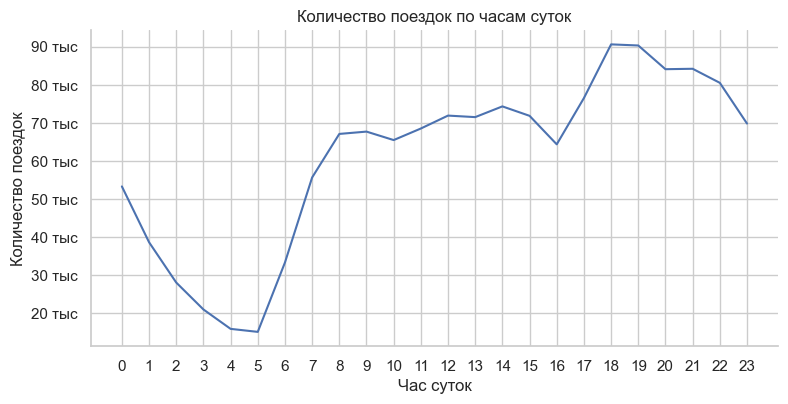

In [99]:
'''
Зависимость количества поездок от часа в сутках
'''
hourly_counts = df.groupby('hour')['id'].count().reset_index()

figure = sns.relplot(
    data=hourly_counts,
    x='hour',
    y='id',
    kind='line',
    height=4,
    aspect=2
)
figure.ax.yaxis.set_major_formatter(plt.FuncFormatter(human_format_y))
plt.title("Количество поездок по часам суток")
plt.xlabel("Час суток")
plt.ylabel("Количество поездок")
plt.xticks(range(0,24))  # все часы от 0 до 23
plt.show()

Вывод: вечером (с 16 до 18) наблюдается пик количества поездок, исходя из имеющейся выборки

11. Нарисуйте на одном графике зависимости количества поездок от часа в сутках для разных месяцев (разные кривые, соответствующие разным месяцам, окрашивайте в разные цвета, воспользуйтесь hue в sns.relplot). Аналогично нарисуйте зависимости количества поездок от часа в сутках для разных дней недели. Сделайте выводы. 

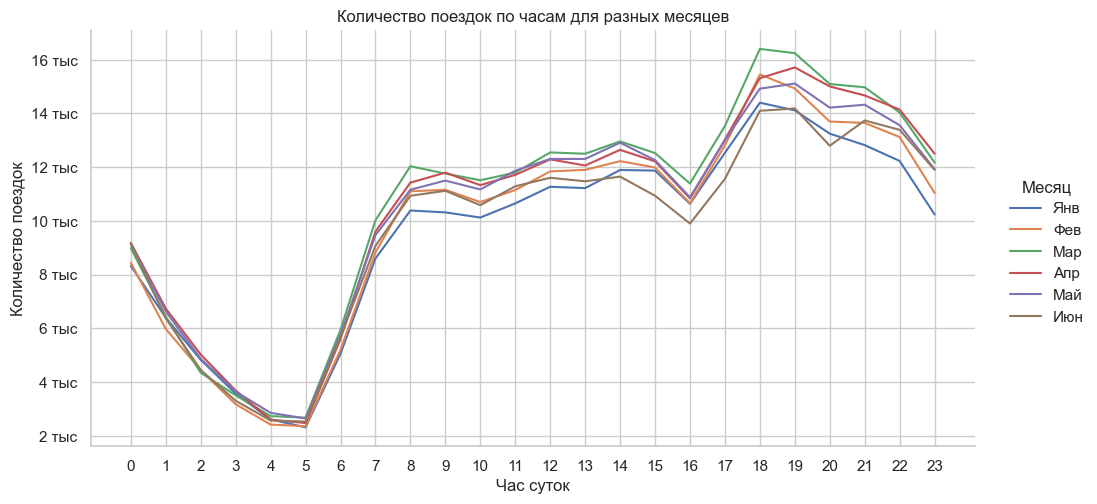

In [100]:
'''
Зависимость количества поездок по часам для разных месяцев
'''

monthly_hourly = df.groupby(['month_name','hour'])['id'].count().reset_index()

figure = sns.relplot(
    data=monthly_hourly,
    x='hour',
    y='id',
    hue='month_name',
    kind='line',
    height=5,
    aspect=2,
    hue_order=month_order
)

figure.set(title="Количество поездок по часам для разных месяцев",
      xlabel="Час суток",
      ylabel="Количество поездок")
figure.ax.yaxis.set_major_formatter(plt.FuncFormatter(human_format_y))
plt.xticks(range(0,24))  # все часы от 0 до 23

figure._legend.set_title("Месяц") 
plt.show()

Вывод: весной наблюдается пик количества поездок. Начиная с 5 до 8, с 15 часов до 18 осуществляется рост числа поездок в любое время года.

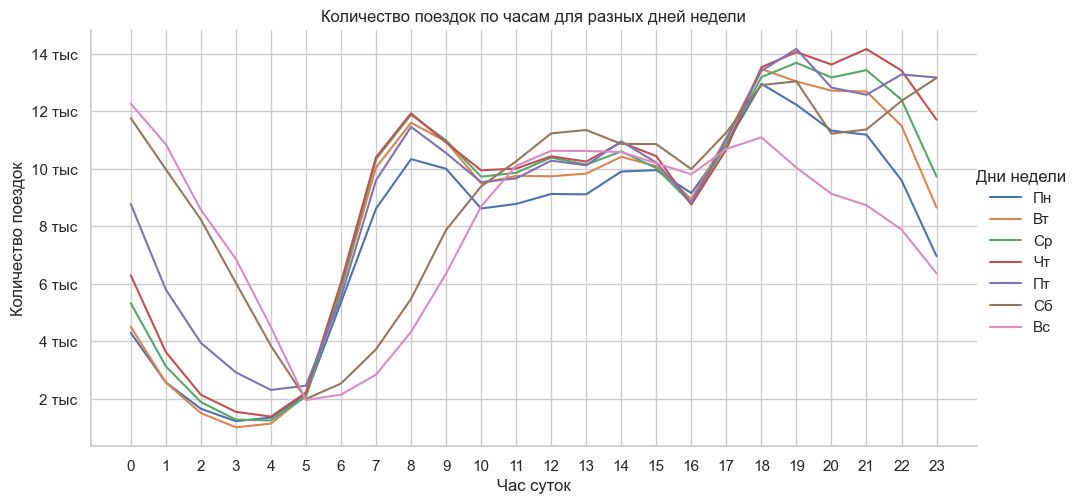

In [101]:
'''
Зависимость количества поездок по часам для разных дней недели
'''

hourly_weekday = df.groupby(['day_name','hour'])['id'].count().reset_index()

figure = sns.relplot(
    data=hourly_weekday,
    x='hour',
    y='id',
    hue='day_name',
    kind='line',
    height=5,
    aspect=2,
    hue_order=weekday_order
)

figure.set(title="Количество поездок по часам для разных дней недели",
      xlabel="Час суток",
      ylabel="Количество поездок")

plt.xticks(range(0,24))  # все часы от 0 до 23
figure.ax.yaxis.set_major_formatter(plt.FuncFormatter(human_format_y))
plt.xticks(range(0,24))  # все часы от 0 до 23

figure._legend.set_title("Дни недели")
plt.show()

Вывод: в будни наблюдается рост числа поездок с 5 до 8, с 16 до 18. На выходных рост поездок гораздо менее быстрый, с 18 до 23 количество поездок падает

 12. Выделяются ли какие-нибудь дни недели? Месяца? Время суток? С чем это связано? 
    ```
    По дням недели: В будние дни (понедельник-четверг) наблюдается монотонный рост количества поездок в течение дня. Пятница выделяется как день с максимальным пиком поездок, что, вероятно, связано с началом выходных. В выходные дни количество поездок монотонно убывает, что может объясняться меньшей деловой активностью и более расслабленным ритмом жизни.

    По времени суток: Выявлены два ярко выраженных периода роста. Утренний рост с 5 до 8 часов связан с началом рабочего дня и поездками на работу. Вечерний пик с 16 до 18 часов является максимальным за сутки и объясняется массовым возвращением людей с работы, а также поездками по личным делам после трудового дня. В выходные вечерний спад начинается раньше (после 18 часов).

    По месяцам: Весна выделяется как сезон с пиковым количеством поездок. Это может быть связано с улучшением погодных условий, увеличением мобильности населения после зимнего периода, а также с сезонными мероприятиями и праздниками.
    ```

13. По обучающей выборке нарисуйте график зависимости среднего логарифма 
времени поездки от дня недели. Затем сделайте то же самое, но для часа в сутках и 
дня в году. 

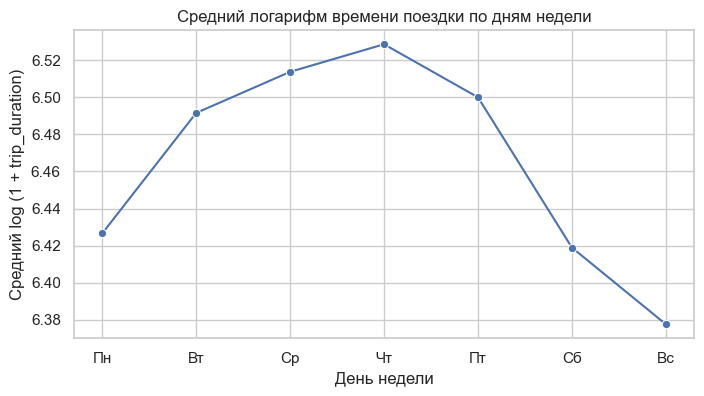

In [102]:
'''
Средний логарифм по дням недели
'''
mean_log_by_weekday = df.groupby('day_of_week')['log_trip_duration'].mean().reset_index()
mean_log_by_weekday['day_name'] = mean_log_by_weekday['day_of_week'].map(weekday_labels)

sns.set_theme(style='whitegrid')
plt.figure(figsize=(8,4))
sns.lineplot(data=mean_log_by_weekday, x='day_name', y='log_trip_duration', marker='o')
plt.title("Средний логарифм времени поездки по дням недели")
plt.xlabel("День недели")
plt.ylabel("Средний log (1 + trip_duration)")
plt.show()

![](./images/task11_count_weekdays.png)

Вывод: Кривые похожи по структуре, но амплитуда меньше. Дело в том, что log_trip_duration сглаживает выбросы, поэтому пики утреннего и вечернего времени не так резко выражены, как на графике количества поездок.

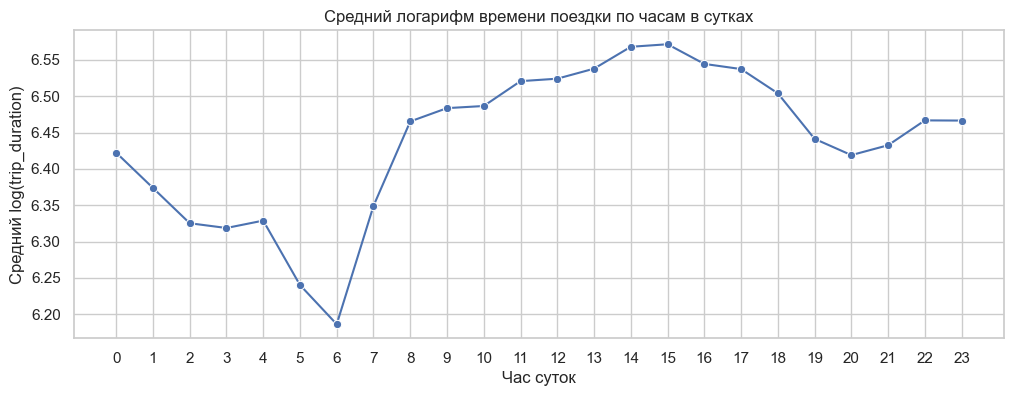

In [103]:
'''
Средний логарифм по часам в сутках
'''

mean_log_by_hour = df.groupby('hour')['log_trip_duration'].mean().reset_index()

plt.figure(figsize=(12,4))
sns.lineplot(data=mean_log_by_hour, x='hour', y='log_trip_duration', marker='o')
plt.title("Средний логарифм времени поездки по часам в сутках")
plt.xlabel("Час суток")
plt.ylabel("Средний log(trip_duration)")
plt.xticks(range(0,24))
plt.show()


![Анализ выбросов](./images/task11_count_hourly.png)

Вывод: Кривые похожи по структуре, но амплитуда меньше. Дело в том, что log_trip_duration сглаживает выбросы, поэтому пики утреннего и вечернего времени не так резко выражены, как на графике количества поездок.

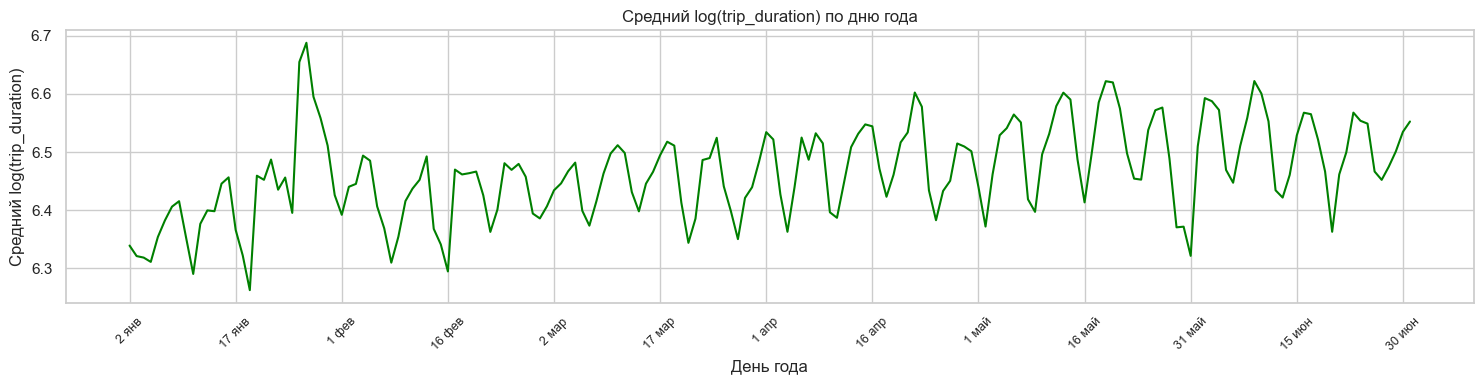

In [104]:
''' 
Средний логарифм по дню года
'''
mean_log_by_day = df.groupby(df['pickup_datetime'].dt.dayofyear)['log_trip_duration'].mean().reset_index()
mean_log_by_day.columns = ['day_of_year', 'mean_log_trip']

# создаем человекочитаемые метки для X
xticklabels = [
    f"{d.day} {months_ru[d.month-1]}"
    for d in pd.to_datetime(mean_log_by_day['day_of_year'], origin=f'{df["pickup_datetime"].dt.year.min()}-01-01', unit='D')
]

fig, axes = plt.subplots(figsize=(15, 4))
sns.lineplot(data=mean_log_by_day, x='day_of_year', y='mean_log_trip', color='green', ax=axes)

axes.set_title("Средний log(trip_duration) по дню года")
axes.set_xlabel("День года")
axes.set_ylabel("Средний log(trip_duration)")

# подписи через каждые 15 дней
plt.xticks(mean_log_by_day['day_of_year'][::15], xticklabels[::15], rotation=45, fontsize=9)
plt.tight_layout()
plt.show()



![](./images/task8_count_yearday.png)

14. Похожи ли графики зависимости логарифма времени поездки от дня недели и от 
часа в сутках на аналогичные графики для количества поездок? Почему? 

    Кривые похожи по структуре, но амплитуда меньше.
    Дело в том, что log_trip_duration сглаживает выбросы (очень длинные поездки), поэтому пики утреннего и вечернего времени не так резко выражены, как на графике количества поездок.

Что происходит со средним логарифма времени поездки в те два аномальных периода, 
что мы видели выше? Почему так происходит? 

    Средний log_trip_duration там выше обычного.
    Почему? Потому что аномально коротких поездок почти нет, а длинные поездки дают высокий логарифм -> среднее увеличивается.

Наблюдаете ли вы какой-нибудь 
тренд на графике зависимости log_trip_duration от номера дня в году? 

    В феврале наблюдается рост числа поездок


15. Добавьте следующие признаки на основе pickup_datetime: 
a. День недели 
b. Месяц 
c. Час 
d. Является ли период аномальным (два бинарных признака, соответствующие 
двум аномальным периодам) 
e. Номер дня в году 

In [105]:
#  аномальные дни у нас были - 23 и 24:
anom1_days = [23, 24]  # первый аномальный период
anom2_days = []        # второй?

# создаем бинарные признаки
df['anom_period1'] = df['day_of_year'].isin(anom1_days).astype(int)
df['anom_period2'] = df['day_of_year'].isin(anom2_days).astype(int)

#остальные были созданы ранее

16. Какие из признаков стоит рассматривать как категориальные, а какие - как численные? Почему? 

Признаки:

    День недели (day_of_week / day_name)	

        категориальный	

            Не числовой порядок: 0 (Пн) не “меньше” 6 (Вс) в смысле величины.

    Месяц (month / month_name)	

        категориальный

            Аналогично: Янв–Дек - категории, а не непрерывная величина.

    Час (hour)	

        можно рассматривать как категориальный

            Хочется отразить цикличность (утро/вечер)

    Номер дня в году (day_of_year)	

        численный	

            Показывает рост/спад по времени, есть порядок и расстояния между днями.

    Бинарные признаки аномалий (anom_period1, anom_period2)	

            категориальные	
            
                Два состояния: 0/1.

17. Нарисуйте на карте точки начала или конца поездки. Какие две точки выделяются на карте? 

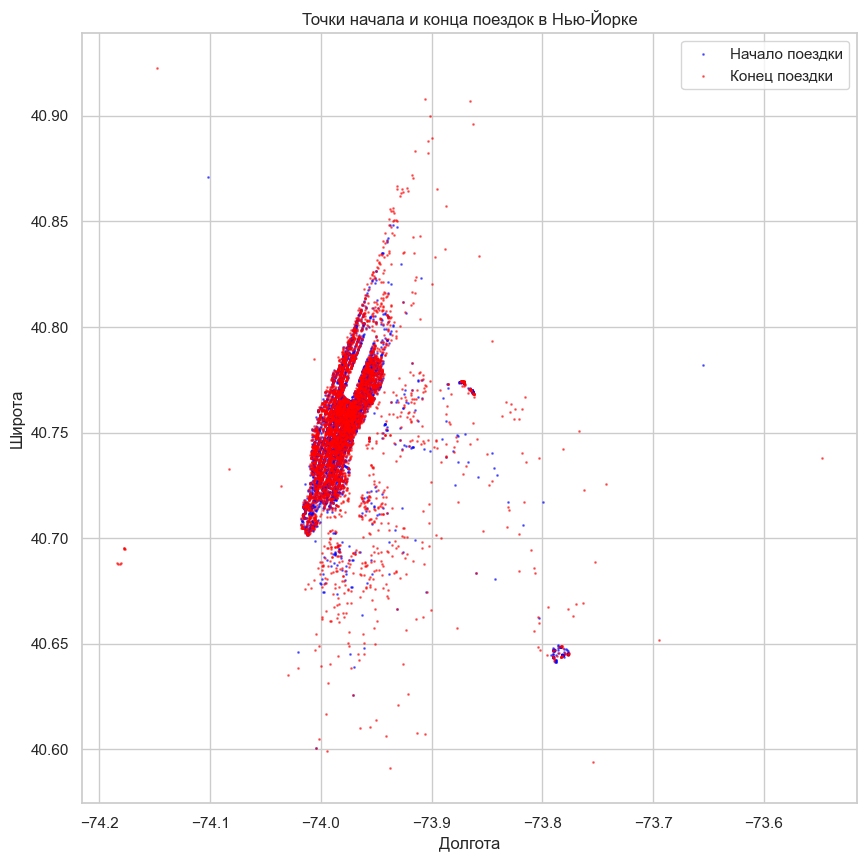

In [106]:
# Ограничим выборку для визуализации, чтобы график был читаемым
sample_df = df.sample(n=5000, random_state=42)

# Настроим фигуру
plt.figure(figsize=(10,10))

# Точки начала поездки
plt.scatter(
    sample_df['pickup_longitude'], 
    sample_df['pickup_latitude'], 
    s=1, alpha=0.5, label='Начало поездки', color='blue'
)

# Точки конца поездки
plt.scatter(
    sample_df['dropoff_longitude'], 
    sample_df['dropoff_latitude'], 
    s=1, alpha=0.5, label='Конец поездки', color='red'
)

plt.title("Точки начала и конца поездок в Нью-Йорке")
plt.xlabel("Долгота")
plt.ylabel("Широта")
plt.legend()
plt.show()

1 выраженная точка:
Адрес: 430, Западная 28-я стрит, Chelsea District, Manhattan Community Board 4, Манхэттен, округ Нью-Йорк, Нью-Йорк, 10001, Соединённые Штаты Америки
2 точка:
Адрес: Cargo 21, Куинс, округ Куинс, Нью-Йорк, 11430, Соединённые Штаты Америки
Kennedy Airport Terminal 7

18. Посчитайте кратчайшее расстояние поездки и запишите его в колонку haversine. (Мы 
не можем посчитать точное расстояние, которое необходимо преодолеть такси, но 
мы можем его оценить, посчитав кратчайшее расстояние между точками начала и 
конца поездки. Чтобы корректно посчитать расстояние между двумя точками на 
Земле, можно использовать функцию haversine.). 

In [107]:
df['haversine'] = df.apply(
    lambda row: haversine(
        (row['pickup_latitude'], row['pickup_longitude']),
        (row['dropoff_latitude'], row['dropoff_longitude']),
        unit=Unit.KILOMETERS
    ),
    axis=1
)

df[['pickup_longitude','pickup_latitude','dropoff_longitude','dropoff_latitude','haversine']].head()

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,haversine
0,-73.982155,40.767937,-73.964630,40.765602,1.498523
1,-73.980415,40.738564,-73.999481,40.731152,1.805510
2,-73.979027,40.763939,-74.005333,40.710087,6.385107
3,-74.010040,40.719971,-74.012268,40.706718,1.485500
4,-73.973053,40.793209,-73.972923,40.782520,1.188590


19. Запишите логарифм haversine в отдельную колонку. Убедитесь, что логарифм 
расстояния лучше коррелирует с логарифмом времени поездки, чем просто 
расстояние. 

In [108]:
# логарифм расстояния (км)
df['log_haversine'] = np.log1p(df['haversine'])

# логарифм времени поездки
df['log_trip_duration'] = np.log1p(df['trip_duration'])

# проверим корреляцию
corr = df[['log_haversine', 'log_trip_duration']].corr().iloc[0,1]
print(f"Корреляция log(haversine) с log(trip_duration): {corr:.3f}")

# для сравнения: корреляция обычного haversine с trip_duration
corr_raw = df[['haversine', 'trip_duration']].corr().iloc[0,1]
print(f"Корреляция haversine с trip_duration: {corr_raw:.3f}")


Корреляция log(haversine) с log(trip_duration): 0.750
Корреляция haversine с trip_duration: 0.152


log(haversine) действительно показывает более линейную связь с log(trip_duration), потому что продолжительность поездки распределена сильно скошенно, а расстояния могут сильно варьироваться.

20. Посчитайте среднюю скорость для каждой поездки, разделив haversine на 
trip_duration, и нарисуйте гистограмму ее распределения. 

In [109]:
# время (ч)
df['trip_duration_hr'] = df['trip_duration'] / 3600

# ср скорость (км/ч)
df['speed_kmh'] = df['haversine'] / df['trip_duration_hr']

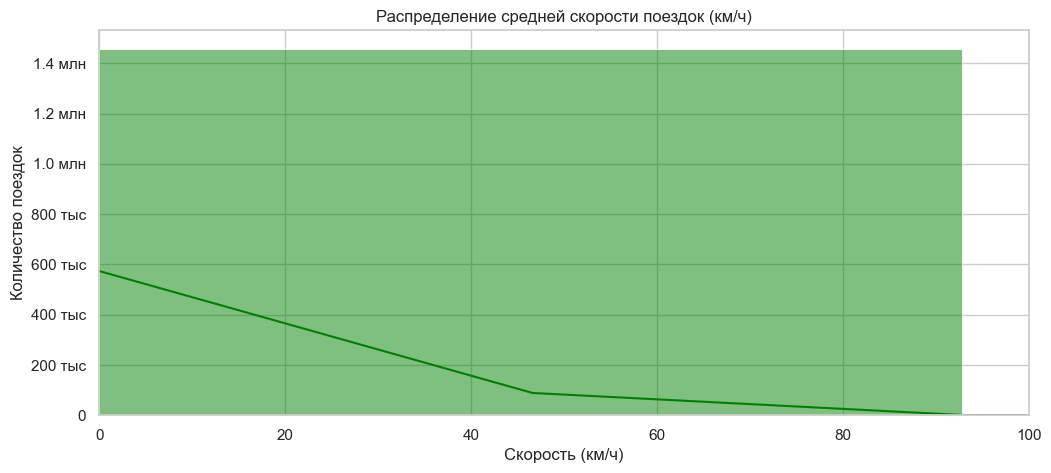

In [110]:
# проверю статистику
#print(df['speed_kmh'].describe())

fig, axes = plt.subplots(figsize=(12, 5))

sns.histplot(
    df['speed_kmh'], 
    bins=100, 
    kde=True, 
    color='green',
    ax=axes
)
    
axes.set_xlim(0, 100)  # убираю экстремальные выбросы
axes.yaxis.set_major_formatter(ticker.FuncFormatter(human_format_y))
axes.set_title("Распределение средней скорости поездок (км/ч)")
axes.set_xlabel("Скорость (км/ч)")
axes.set_ylabel("Количество поездок")
plt.show()


Ограничил скорость, дабы не портить график выбросами (ошибки GPS в основном)
Вывод: в городе средняяя скорость такси от 20 км/ч до 60 км/ч

21. Нарисуйте гистограмму по объектам, для которых значение скорости получилось 
разумным. 

Осталось поездок: 1444717 из 1458640


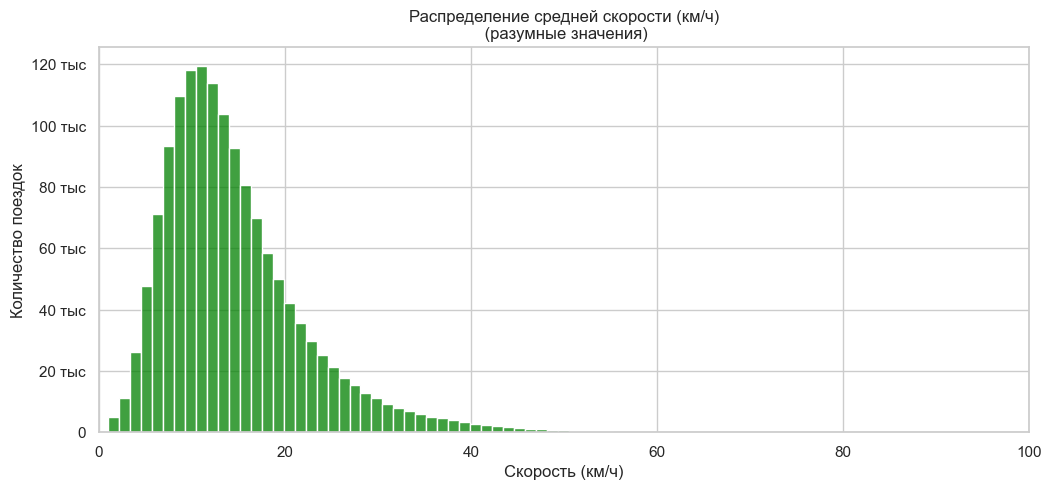

In [111]:
# отфильтрую разумные скорости
df_speed_ok = df[
    (df['speed_kmh'] > 1) &
    (df['speed_kmh'] < 60)
]

print(f"Осталось поездок: {len(df_speed_ok)} из {len(df)}")

fig, axes = plt.subplots(figsize=(12, 5))
sns.histplot(
    df_speed_ok['speed_kmh'],
    bins=50,
    kde=False,
    color='green'
)
axes.set_xlim(0, 100)  # убираю экстремальные выбросы
axes.yaxis.set_major_formatter(ticker.FuncFormatter(human_format_y))
axes.set_title("Распределение средней скорости (км/ч)\n (разумные значения)")
axes.set_xlabel("Скорость (км/ч)")
axes.set_ylabel("Количество поездок")

plt.show()


Вывод: после фильтрации нереалистичных значений скорости (менее 1 км/ч и более 60 км/ч) распределение становится близким к нормальному. Основная масса поездок имеет среднюю скорость в диапазоне 15–30 км/ч, что соответствует городскому движению в Нью-Йорке. Это подтверждает корректность признака haversine и возможность использования скорости как дополнительного признака в модели.

22. Для каждой пары (день недели, час суток) посчитайте медиану скоростей. Нарисуйте 
с помощью sns.heatmap график, где по осям будут дни недели и часы, а в качестве 
значения функции - медиана скорости. Посмотрите внимательно на график и 
скажите, в какие моменты времени скорость минимальна; максимальна. 

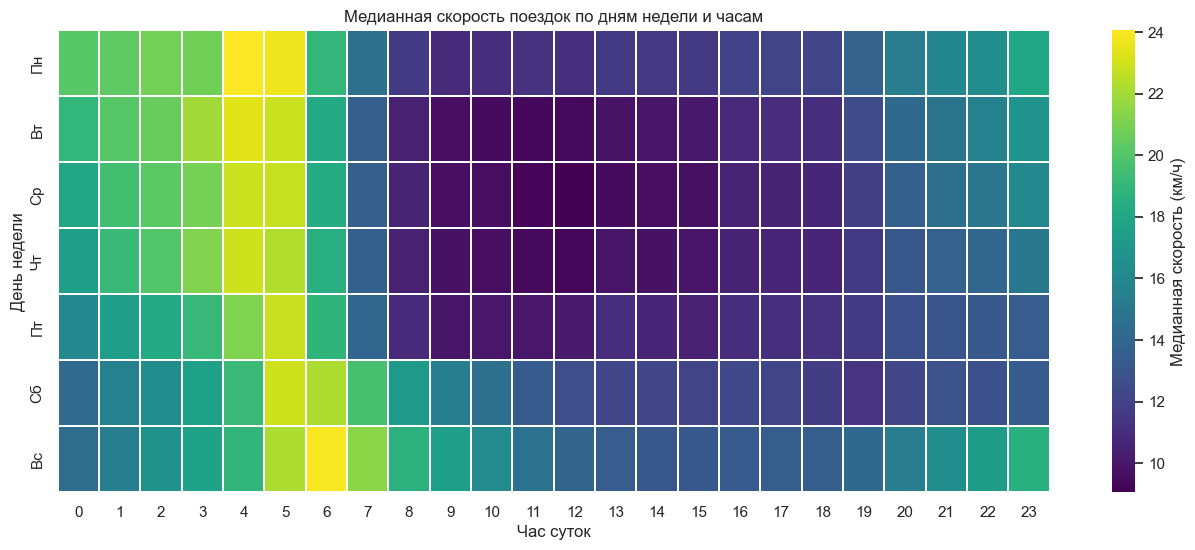

In [ ]:
# считаю медиану скорости по (день недели, час)
speed_median = (
    df_speed_ok
    .groupby(['day_name', 'hour'])['speed_kmh']
    .median()
    .reset_index()
)

heatmap_data = speed_median.pivot(
    index='day_name',
    columns='hour',
    values='speed_kmh'
)

# зафиксирую порядок дней недели
heatmap_data = heatmap_data.reindex(weekday_order)

plt.figure(figsize=(16, 6))

axes = sns.heatmap(
    heatmap_data,
    cmap='viridis',
    linewidths=0.3,
    cbar_kws={'label': 'Медианная скорость (км/ч)'}
)

plt.title("Медианная скорость поездок по дням недели и часам")
plt.xlabel("Час суток")
plt.ylabel("День недели")
plt.show()

Вывод: в будние и выходные дни с 0 до 7 медианная скорость максимальная, минимальная - в будние дни с 8 до 16, связано это с загруженностью дорог. В выходные дни скорость в это время скорость выше.

23. Создайте признаки "поездка совершается в период пробок" и "поездка совершается 
в период свободных дорог" (естественно, они не должны зависеть от скорости!) 

In [124]:
# признак "поездка в период пробок"
df['is_rush_hour'] = (
    (df['day_of_week'] < 5) &   # будни
    (df['hour'].between(8, 16))
).astype(int)

# признак "поездка в период свободных дорог"
df['is_free_road'] = (
    (df['hour'].between(0, 7))
).astype(int)

df[['day_name', 'hour', 'is_rush_hour', 'is_free_road']].head(10)

,day_name,hour,is_rush_hour,is_free_road
0,Пн,17,0,0
1,Вс,0,0,1
2,Вт,11,1,0
3,Ср,19,0,0
4,Сб,13,0,0
5,Сб,22,0,0
6,Пт,22,0,0
7,Сб,7,0,1
8,Пт,23,0,0
9,Чт,21,0,0


24. Как уже было замечено выше, на карте выделяются две точки. Для каждого из этих 
объектов добавьте два признака: началась ли поездка из этого объекта и 
закончилась ли поездка в этом объекте. 

In [116]:
# Chelsea (West 28th St, Manhattan)
CHELSEA_LAT = 40.747
CHELSEA_LON = -74.003

# JFK Airport (Terminal 7)
JFK_LAT = 40.649
JFK_LON = -73.783

# радиус окрестности (примерно 300–500 метров)
DELTA = 0.005

def in_area(lat, lon, center_lat, center_lon, delta=DELTA):
    return (
        (lat.between(center_lat - delta, center_lat + delta)) &
        (lon.between(center_lon - delta, center_lon + delta))
    )

In [117]:
'''Признаки для Chelsea - плотная городская точка'''
df['pickup_chelsea'] = in_area(
    df['pickup_latitude'], df['pickup_longitude'],
    CHELSEA_LAT, CHELSEA_LON
).astype(int)

df['dropoff_chelsea'] = in_area(
    df['dropoff_latitude'], df['dropoff_longitude'],
    CHELSEA_LAT, CHELSEA_LON
).astype(int)

'''Признаки для JSA - аэропорт'''
df['pickup_jfk'] = in_area(
    df['pickup_latitude'], df['pickup_longitude'],
    JFK_LAT, JFK_LON
).astype(int)

df['dropoff_jfk'] = in_area(
    df['dropoff_latitude'], df['dropoff_longitude'],
    JFK_LAT, JFK_LON
).astype(int)

df[
    [
        'pickup_chelsea', 'dropoff_chelsea',
        'pickup_jfk', 'dropoff_jfk'
    ]
].mean()

pickup_chelsea     0.022286
dropoff_chelsea    0.019942
pickup_jfk         0.009499
dropoff_jfk        0.002433
dtype: float64

25. Для каждого из созданных признаков нарисуйте "ящик с усами" (sns.boxplot) 
распределения логарифма времени поездки. Хорошими ли получились эти 
признаки? 

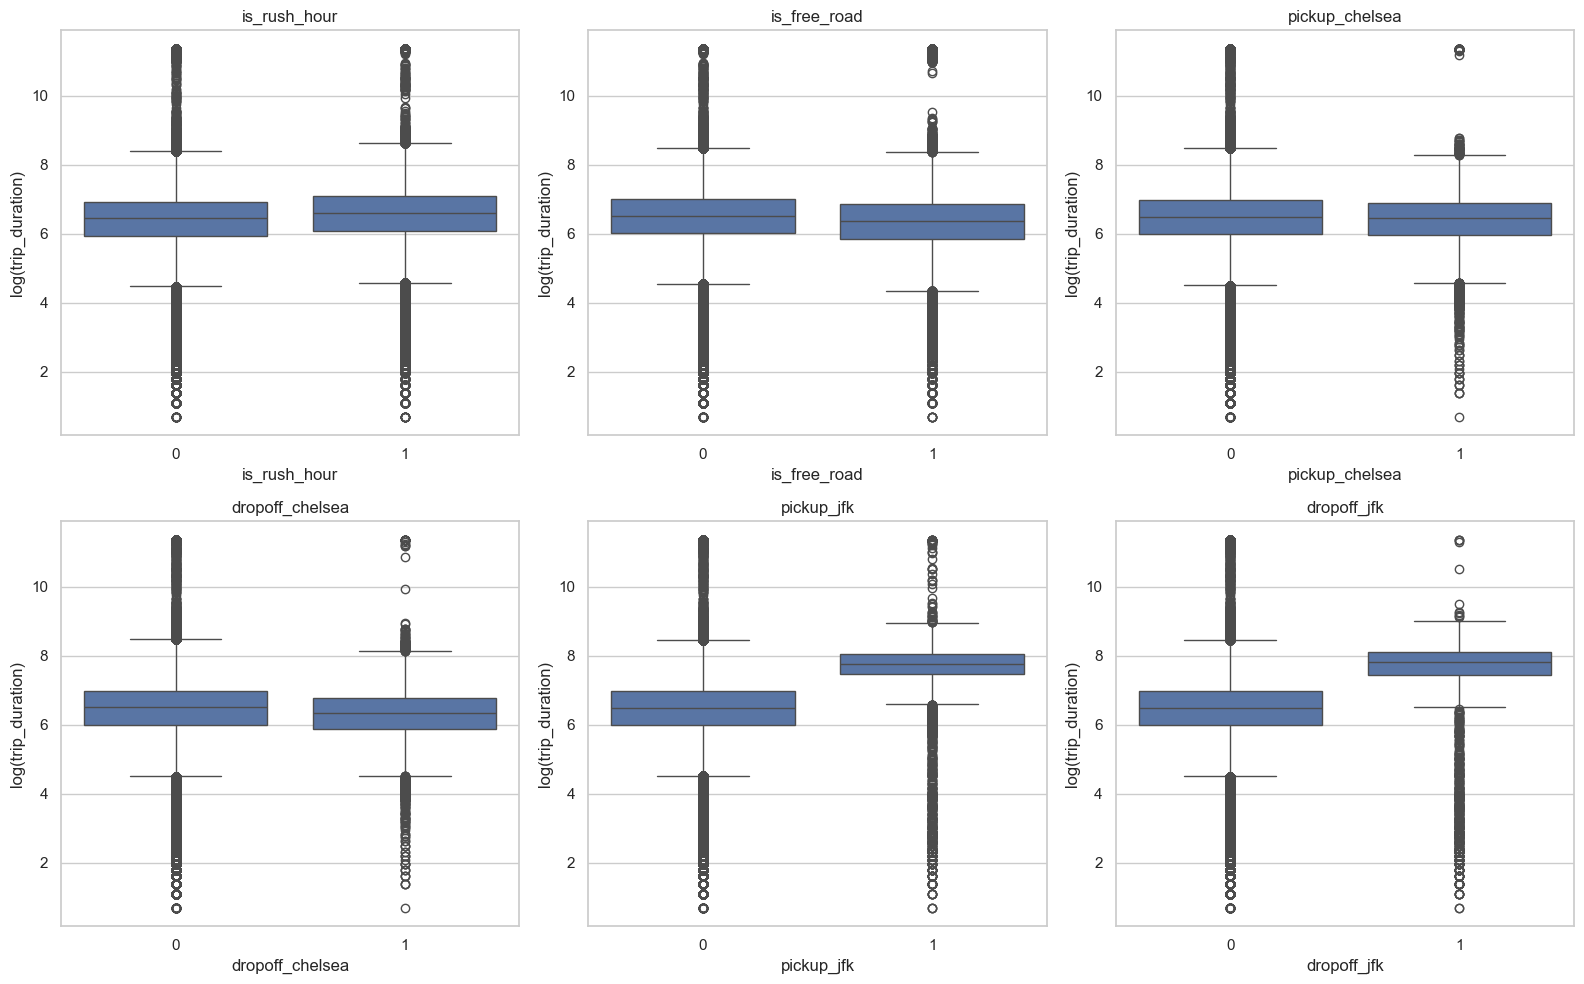

In [125]:
binary_features = [
    'is_rush_hour',
    'is_free_road',
    'pickup_chelsea',
    'dropoff_chelsea',
    'pickup_jfk',
    'dropoff_jfk'
]

plt.figure(figsize=(16, 10))

for i, feature in enumerate(binary_features, 1):
    plt.subplot(2, 3, i)
    
    sns.boxplot(
        data=df,
        x=feature,
        y='log_trip_duration'
    )
    
    plt.title(feature)
    plt.xlabel(feature)
    plt.ylabel('log(trip_duration)')

plt.tight_layout()
plt.show()

Вывод: значения лежат в основном в ящике, но также есть много точек на границах, связано это с множеством невалидных данных.

26. Посчитайте, сколько есть уникальных значений у каждого из этих признаков 
vendor_id, passenger_count и store_and_fwd_flag. Почему каждый из этих признаков 
может быть потенциально полезным? 

In [126]:
features = ['vendor_id', 'passenger_count', 'store_and_fwd_flag']

for f in features:
    n_unique = df[f].nunique()
    print(f"{f}: {n_unique} уникальных значений")


vendor_id: 2 уникальных значений
passenger_count: 10 уникальных значений
store_and_fwd_flag: 2 уникальных значений


🔹 Интерпретация

vendor_id

    Типично 2 уникальных значения (два поставщика такси NYC)

    Почему полезно: разные поставщики могут иметь разные типы тарифов, зоны работы, поведение водителей влияет на продолжительность поездки.

passenger_count

    10 уникальных значений

    Почему полезно: количество пассажиров влияет на скорость поездки.

store_and_fwd_flag

    Два значения: Y / N

    Почему полезно: указывает, была ли запись временно сохраненаб косвенно может отражать проблемы с соединением, редкие маршруты или задержки.

27. Постройте "ящики с усами" распределений логарифма времени поездки в 
зависимости от значений каждого из признаков. 

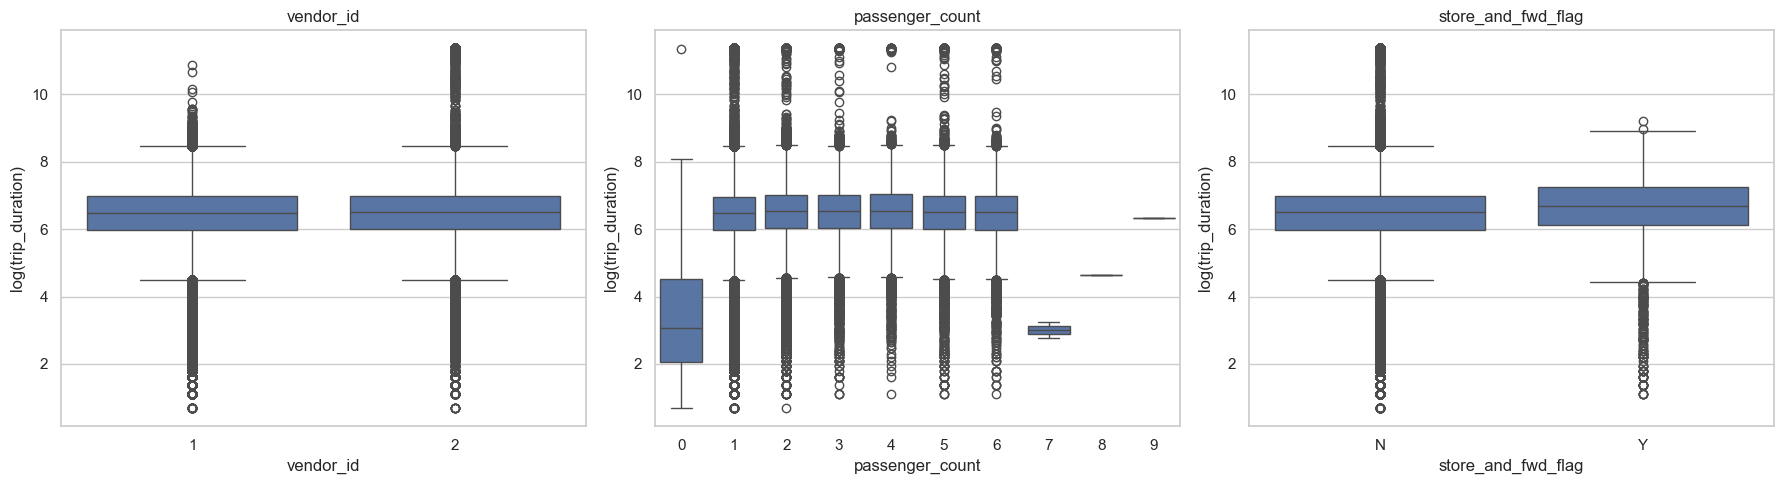

In [127]:
df['log_trip_duration'] = np.log1p(df['trip_duration'])

plt.figure(figsize=(18, 5))

for i, f in enumerate(features, 1):
    plt.subplot(1, 3, i)
    
    sns.boxplot(
        data=df,
        x=f,
        y='log_trip_duration'
    )
    
    plt.title(f)
    plt.xlabel(f)
    plt.ylabel('log(trip_duration)')

plt.tight_layout()
plt.show()


vendor_id:

    Медиана может немного отличаться между поставщиками → полезно для модели

passenger_count:

    Более крупные группы пассажиров иногда увеличивают медиану времени поездки

store_and_fwd_flag:

    Y - чаще чуть больше trip_duration (иногда задержка передачи)

    N - обычные поездки

Ящик с усами наглядно показывает, что все признаки имеют различия в распределении времени поездки, они информативны.

28. Посчитайте количество признаков до и после кодирования категориальных 
признаков.

In [4]:
print("Количество признаков до кодирования:", df.shape[1])
df_encoded = pd.get_dummies(df, columns=['vendor_id', 'passenger_count', 'store_and_fwd_flag'], drop_first=False)
print("Количество признаков после кодирования:", df_encoded.shape[1])

Количество признаков до кодирования: 11
Количество признаков после кодирования: 22


Вывод: Количество признаков увеличилось, потому что каждый уникальный вариант превращается в отдельный бинарный столбец.